# Exercise 1: Load a Generative AI Model

In [3]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
# import warningswarnings.filterwarnings('ignore')
from transformers import pipeline, GPT2LMHeadModel, GPT2Tokenizer
import torch
import gzip, json, random, time
import seaborn as sns
from tabulate import tabulate

c:\Users\1030817\Dev\lab-gcai-luiz\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Global variable to store AI models
ai_models = {}
def setup_ai_models():
    """Setup available AI models"""

    global ai_models
    print("Loading AI models for demonstration...")

    ai_models['text_generator'] = pipeline(
        "text-generation",
        model="gpt2",
        max_length=100
    )

    ai_models['sentiment'] = pipeline(
        "sentiment-analysis",
        model="distilbert-base-uncased-finetuned-sst-2-english"
    )

    ai_models['classifier'] = pipeline(
        "zero-shot-classification",
        model="facebook/bart-large-mnli"
    )
    print("✅ Models loaded successfully!")
    return ai_models

# Setup models and run demos
ai_models = setup_ai_models()

Loading AI models for demonstration...


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 642.54it/s]
[transformers] Passing `generation_config` together with generation-related arguments=({'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Loading weights: 100%|██████████| 515/515 [00:01<00:00, 404.79it/s]


✅ Models loaded successfully!


# Exercise 2: First Experiment with Text Generation

In [5]:
def demonstrate_text_generation():
    """Show how AI generates text"""
    print("\nTEXT GeNERATION DEMO")
    print("-" * 50)

    prompts = [
        "Does AI have consciousness?",
    ]

    if 'text_generator' in ai_models:
        for prompt in prompts:
            try:
                result = ai_models['text_generator'](
                    prompt,
                    max_length=1000,
                    num_return_sequences=1,
                    temperature=0.7
                )
                generated = result[0]['generated_text']
                print(f"Prompt: {prompt}")
                print("AI Response:")
                print(generated)
                print("-" * 50)
            except Exception as e:
                print(f"Error with prompt: {prompt}")
                print(f"Details: {e}")
                print("-" * 50)

demonstrate_text_generation()

[transformers] Passing `generation_config` together with generation-related arguments=({'temperature', 'max_length', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.



TEXT GeNERATION DEMO
--------------------------------------------------


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Prompt: Does AI have consciousness?
AI Response:
Does AI have consciousness?

In his book, "Why Are Humans Being Conscious?" Hawking says that we're "thinking of ourselves as robots that are being controlled by AI." This is "the most pervasive assumption of AI, but it is also the most pervasive." If it is true that we believe in AI, why would humans be "thinking of themselves as robots that are being controlled by AI?"

But what if we're not conscious of our own existence and therefore should have no idea what we are doing with our lives?

"I am not doing anything that is going to give me an idea of what I'm doing," Hawking says.

"I'm not doing anything that helps me to understand the world or, for that matter, the real world."

And that is a question that is being tackled by neuroscientists and psychologists.

"We're not talking about something that we do that we do not know," says David H. Dyson, an assistant professor of psychology at the University of California, Berkeley.

"We're

# Exercise 3: Content Analysis and Classification

In [6]:
def demonstrate_content_and_classification():
    """Demo for sentiment analysis and text classification"""
    # --- Sentiment Analysis ---
    reviews = [
    "This product is amazing! Best purchase ever!",
    "Terrible quality, waste of money.",
    "It's okay, nothing special but does the job."
    ]
    if 'sentiment' in ai_models:
        print("\nSentiment Analysis")
        for review in reviews:
            result = ai_models['sentiment'](review)[0]
            print(f"Review: {review}")
            print(f"Sentiment: {result['label']} | Confidence Score: {result['score']:.2f}\n")
    texts = [
        "AI is transforming healthcare by improving diagnosis accuracy.",
        "The football team won their championship game yesterday.",
        "Investors are excited about the growth of renewable energy.",
        "The terrain is very good for agriculture! A lot of nutrients around."
        ]
    labels = ["Technology", "Sports", "Business", "Health", "Geography"]

    if 'classifier' in ai_models:
        print("\nText Classification")
        for text in texts:
            result = ai_models['classifier'](text, candidate_labels=labels)
            print(f"Text: {text}")
            print(f"Category: {result['labels'][0]} | Confidence Score: {result['scores'][0]:.2f}\n")

# Run the demo
demonstrate_content_and_classification()

    


Sentiment Analysis
Review: This product is amazing! Best purchase ever!
Sentiment: POSITIVE | Confidence Score: 1.00

Review: Terrible quality, waste of money.
Sentiment: NEGATIVE | Confidence Score: 1.00

Review: It's okay, nothing special but does the job.
Sentiment: POSITIVE | Confidence Score: 1.00


Text Classification
Text: AI is transforming healthcare by improving diagnosis accuracy.
Category: Technology | Confidence Score: 0.64

Text: The football team won their championship game yesterday.
Category: Sports | Confidence Score: 0.99

Text: Investors are excited about the growth of renewable energy.
Category: Business | Confidence Score: 0.43

Text: The terrain is very good for agriculture! A lot of nutrients around.
Category: Geography | Confidence Score: 0.58



# Exercise 4: AI Collaboration: Combining Generation and Analysis

In [7]:
# Global variable to store workflow results
results = {}
def ai_collaboration():
    """Generator + Sentiment + Classifier working together"""
    product = "Laptop Pro"
    # Step 1: Generate description
    desc = ai_models['text_generator'](
        f"{product} features",
        max_new_tokens=20,
        temperature=0.7
    )[0]['generated_text']

    desc = desc.replace(f"{product} features", "").strip()
    full_text = f"{product} features {desc}"

    # Step 2: Sentiment analysis
    mood = ai_models['sentiment'](full_text)[0]
    sentiment = f"{mood['label']} ({mood['score']:.2f})"

    # Step 3: Classification
    categories = ["Electronics", "Sports", "Fashion"]
    cat = ai_models['classifier'](full_text, candidate_labels=categories)

    classification = f"{cat['labels'][0]} ({cat['scores'][0]:.2f})"

    # Save results
    results['ai_version'] = {
    "text": full_text,
    "sentiment": sentiment,
    "category": classification
    }

    # Print concise results
    print("Generated:", full_text)
    print("Sentiment:", sentiment)
    print("Category:", classification)

# Run the demo
ai_collaboration()

[transformers] Passing `generation_config` together with generation-related arguments=({'temperature', 'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=20) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generated: Laptop Pro features a large number of USB 3.0 ports, a 1.5mm headphone jack, and an
Sentiment: NEGATIVE (0.96)
Category: Electronics (0.59)


# Exercise 5: Human-in-the-Loop: Feedback and AI Rewrite

In [8]:
def step2_human_feedback():
    """Collect human feedback on missing features"""
    original = results.get('ai_version', {}).get('text', 'Laptop Pro')
    print("Original:", original)
    feedback = input("What features should be added? (e.g., battery life, waterproof): ")
    results['human_feedback'] = feedback.strip()
    return feedback

In [9]:
# Step 3: AI improvement
def step3_direct_ai_improvement():
    """GPT-2 rewrites the description using human feedback"""
    original = results.get('ai_version', {}).get('text', '').strip()
    feedback = results.get('human_feedback', '').strip()
    # Short natural prompt (avoids repetition loops)
    prompt = (
        f"Original: {original}\n"
        f"Rewrite the product description to include {feedback}.\n"
    )
    output = ai_models['text_generator'](
        prompt,
        max_new_tokens=120,
        temperature=0.7,
        top_p=0.9,
        pad_token_id=50256,
        return_full_text=False
    )[0]['generated_text']
    improved = output
    # Save for later use
    results['final_improved'] = improved
    print("Improved:", improved)

# Execute steps
step2_human_feedback()
step3_direct_ai_improvement()

Original: Laptop Pro features a large number of USB 3.0 ports, a 1.5mm headphone jack, and an


[transformers] Passing `generation_config` together with generation-related arguments=({'temperature', 'max_new_tokens', 'top_p', 'pad_token_id'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=120) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Improved: 
The Intel Core i7-4790K has been updated to a new CPU cooler.

The new CPU cooler has an Intel Core i7-4790K CPU cooler that supports dual-channel DDR3-1600, 1TB hard drive, dual-channel DDR3-1600, 1TB hard drive, and 2TB hard drive.

Intel Core i7-4790K is designed for the new Intel Core i7-4790K CPU cooler. The new cooler has a dual-channel DDR3-1600, 1TB hard drive, dual-channel DDR3


# Exercise 6: Loading and Exploring the Amazon Reviews Dataset 

In [15]:
import gzip
import simplejson

def parse(path):
  """Parse a .jsonl.gz file line by line"""
  with gzip.open(path, 'rb') as f:
    for line in f:
      yield json.loads(line)

In [28]:
def load_amazon_data(review_path, meta_path, max_records=500):
    """
    Load Amazon review & metadata from .jsonl.gz files
    """
    print("\nLOADING AMAZON DATASET")
    print("=" * 50)
    # ---- Load reviews ----
    print("Reading reviews...")
    reviews = []
    for i, record in enumerate(parse(review_path)):
        reviews.append(record)

        print(f"REVIEW: {i + 1}/{max_records}")
        if i + 1 >= max_records:
            break
        reviews_df = pd.DataFrame(reviews)

        # ---- Load metadata ----
        
        metadata = []
        for i, record in enumerate(parse(meta_path)):
            metadata.append(record)

            # print(f"META: {i + 1}/{max_records}")

            if i + 1 >= max_records:
                break

    metadata_df = pd.DataFrame(metadata)
    print("Data Loaded Successfully!")
    return reviews_df, metadata_df

reviews_df, metadata_df = load_amazon_data(
    "C:/Users/1030817/Dev/lab-gcai-luiz/Video_games.jsonl.gz",
    "C:/Users/1030817/Dev/lab-gcai-luiz/meta_Video_games.jsonl.gz",
    max_records=500
)


LOADING AMAZON DATASET
Reading reviews...
REVIEW: 1/500
REVIEW: 2/500
REVIEW: 3/500
REVIEW: 4/500
REVIEW: 5/500
REVIEW: 6/500
REVIEW: 7/500
REVIEW: 8/500
REVIEW: 9/500
REVIEW: 10/500
REVIEW: 11/500
REVIEW: 12/500
REVIEW: 13/500
REVIEW: 14/500
REVIEW: 15/500
REVIEW: 16/500
REVIEW: 17/500
REVIEW: 18/500
REVIEW: 19/500
REVIEW: 20/500
REVIEW: 21/500
REVIEW: 22/500
REVIEW: 23/500
REVIEW: 24/500
REVIEW: 25/500
REVIEW: 26/500
REVIEW: 27/500
REVIEW: 28/500
REVIEW: 29/500
REVIEW: 30/500
REVIEW: 31/500
REVIEW: 32/500
REVIEW: 33/500
REVIEW: 34/500
REVIEW: 35/500
REVIEW: 36/500
REVIEW: 37/500
REVIEW: 38/500
REVIEW: 39/500
REVIEW: 40/500
REVIEW: 41/500
REVIEW: 42/500
REVIEW: 43/500
REVIEW: 44/500
REVIEW: 45/500
REVIEW: 46/500
REVIEW: 47/500
REVIEW: 48/500
REVIEW: 49/500
REVIEW: 50/500
REVIEW: 51/500
REVIEW: 52/500
REVIEW: 53/500
REVIEW: 54/500
REVIEW: 55/500
REVIEW: 56/500
REVIEW: 57/500
REVIEW: 58/500
REVIEW: 59/500
REVIEW: 60/500
REVIEW: 61/500
REVIEW: 62/500
REVIEW: 63/500
REVIEW: 64/500
REVIEW


EXPLORING AMAZON DATA STRUCTURE

Dataset Sizes
+-----------+--------+-----------+
| Dataset   |   Rows |   Columns |
+===========+========+===========+
| Reviews   |    499 |        10 |
+-----------+--------+-----------+
| Metadata  |    500 |        14 |
+-----------+--------+-----------+

Reviews Columns
+-------------------+
| Column            |
+===================+
| rating            |
+-------------------+
| title             |
+-------------------+
| text              |
+-------------------+
| images            |
+-------------------+
| asin              |
+-------------------+
| parent_asin       |
+-------------------+
| user_id           |
+-------------------+
| timestamp         |
+-------------------+
| helpful_vote      |
+-------------------+
| verified_purchase |
+-------------------+

Metadata Columns
+-----------------+
| Column          |
+=================+
| main_category   |
+-----------------+
| title           |
+-----------------+
| average_rating  |
+-----

C:\Users\1030817\AppData\Local\Temp\ipykernel_27368\88357227.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="rating", data=reviews_df, palette="viridis",


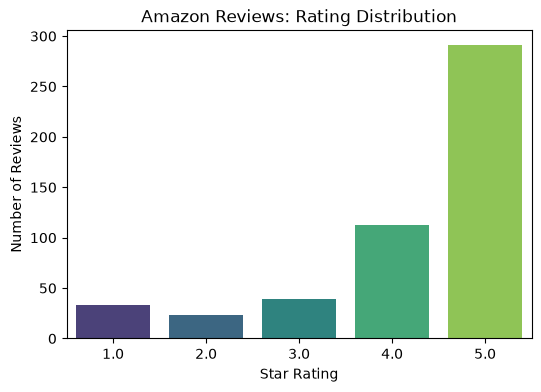

In [29]:
def explore_amazon_data_structure(reviews_df, metadata_df):
    """Explore and display data structure with formatted tables"""
    print("\nEXPLORING AMAZON DATA STRUCTURE")
    print("=" * 50)
    # Dataset sizes
    print("\nDataset Sizes")
    table = [
        ["Reviews", reviews_df.shape[0], reviews_df.shape[1]],
        ["Metadata", metadata_df.shape[0], metadata_df.shape[1]]
    ]
    print(tabulate(table, headers=["Dataset", "Rows", "Columns"], tablefmt="grid"))
    # Column names
    print("\nReviews Columns")
    print(tabulate([[c] for c in reviews_df.columns], headers=["Column"], tablefmt="grid"))
    print("\nMetadata Columns")
    print(tabulate([[c] for c in metadata_df.columns], headers=["Column"], tablefmt="grid"))
    # Sample review
    print("\nSample Review")
    review_sample = reviews_df.iloc[0].to_dict()
    print(tabulate(review_sample.items(), headers=["Field", "Value"], tablefmt="grid"))
    # Sample metadata
    print("\nSample Product Metadata")
    meta_sample = metadata_df.iloc[0].to_dict()
    print(tabulate(meta_sample.items(), headers=["Field", "Value"], tablefmt="grid"))
    # Rating distribution
    if "rating" in reviews_df.columns:
        print("\n Rating Distribution")
        rating_counts = reviews_df['rating'].value_counts().sort_index()
        print(tabulate(rating_counts.reset_index().values,
        headers=["Rating", "Count"], tablefmt="grid"))
        # Plot
        plt.figure(figsize=(6,4))
        sns.countplot(x="rating", data=reviews_df, palette="viridis",
        order=sorted(reviews_df["rating"].dropna().unique()))
        plt.title("Amazon Reviews: Rating Distribution")
        plt.xlabel("Star Rating")
        plt.ylabel("Number of Reviews")
        plt.show()

explore_amazon_data_structure(reviews_df, metadata_df)

# Exercise 7: Applying AI Pipelines to Real Amazon Reviews


 AI-POWERED AMAZON REVIEW DEMO

 Review #1 (Product ID: B07XHN9D3Z)
 I love the idea, but they are seriously weak on how they hold on. They pop off so easy. After falling off about 10 times, now they won’t even stay on without pressure. Great idea, bad design 😟...

VISUAL INSIGHTS


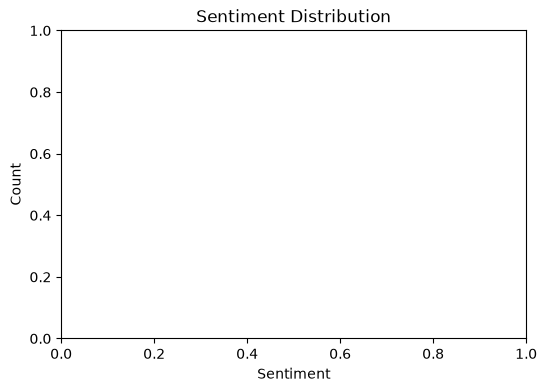


 Review #2 (Product ID: B07BT3N4BT)
 The plug and the jack are two different types.  It doesn't fit the system, therefore, I can't give it feedback on how well it works....

VISUAL INSIGHTS


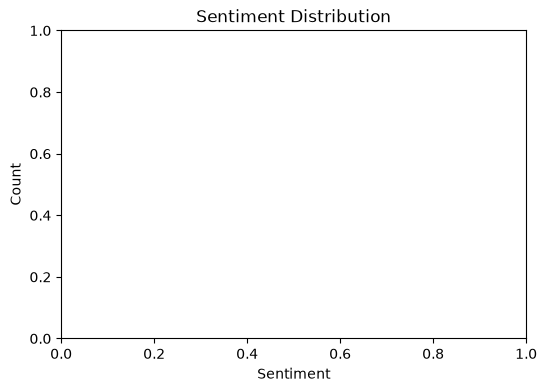


 Review #3 (Product ID: B078Y7X6F7)
 Works great. Fast shipping....

VISUAL INSIGHTS


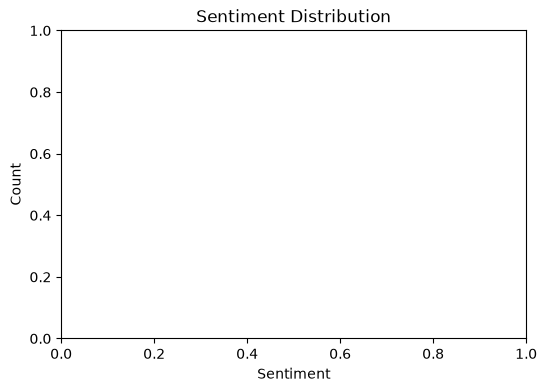


 Review #4 (Product ID: B01A9GDLW8)
 Worked great, improved speeds, I got it too short do I'll be ordering another and using the shorter for another pc, that's currently on a bridge but will go right to the router....

VISUAL INSIGHTS


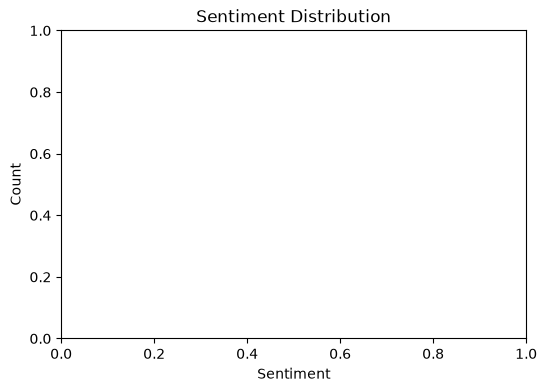


 Review #5 (Product ID: B0B5R5PBBS)
 [[VIDEOID:c90a1b30b08b7e7f29002ffa5c82bb00]] I really enjoy the 60% form factor of this keyboard. The board is solid and high quality and can be connected via Bluetooth, USB cable, or the included wireless receiver. It also comes with a USB cable, keycap puller, and switch puller.<br /><br />My bigg...

VISUAL INSIGHTS


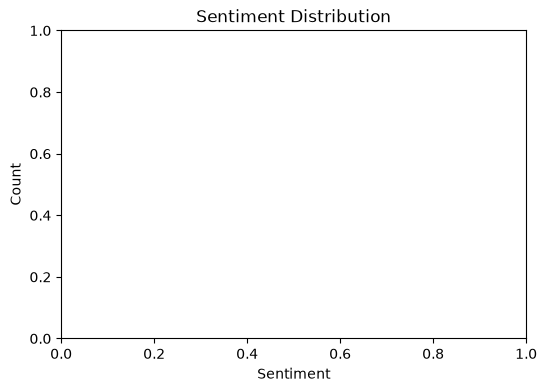

In [ ]:
def ai_amazon_demo(reviews_df, metadata_df, num_reviews=5):
    print("\n AI-POWERED AMAZON REVIEW DEMO")
    print("=" * 55)
    # Candidate labels for zero-shot classifier
    candidate_labels = ["Quality", "Delivery", "Price", "Usability",
    "Durability"]
    # Pick random reviews
    sample_reviews = reviews_df.dropna(subset=['text']).sample(num_reviews)
    sentiments, categories = [], []
    for i, (_, review) in enumerate(sample_reviews.iterrows(), 1):
        text = str(review['text'])[:300]
        asin = review.get('asin', 'Unknown')
        rating = review.get('rating', 0)
        print(f"\n Review #{i} (Product ID: {asin})")
        print(f" {text}...")
        # ---- Sentiment Analysis ----
        if 'sentiment' in ai_models:
            result = ai_models['sentiment'](text)[0]
            sentiment = result['label']
            score = result['score']
        else:
            sentiment, score = ("POSITIVE" if rating >= 4 else "NEGATIVE", 0.9)
            sentiments.append(sentiment)
            print(f" Rating: {rating}")
            print(f" Sentiment: {sentiment} (confidence: {score:.2f})")
            # ---- Classification ----
            if 'classifier' in ai_models:
                classify = ai_models['classifier'](text,
                candidate_labels=candidate_labels)
                top_label = classify['labels'][0]
                cat_score = classify['scores'][0]
            else:
                top_label, cat_score = random.choice(candidate_labels), 0.8
                categories.append(top_label)
                print(f" Key Topic: {top_label} (confidence: {cat_score:.2f})")
                if 'text_generator' in ai_models:
                    prompt = f"Summarize this review in one sentence:\n{text}\nSummary:"
                    generated = ai_models['text_generator'](
                    prompt, max_new_tokens=50, temperature=0.7,
                    pad_token_id=50256
                    )[0]['generated_text']
                    summary = generated.replace(prompt, "").strip()
                else:
                    summary = f"This review mainly talks about {top_label.lower()}."
                    print(f"AI Summary: {summary}")
                    time.sleep(0.5)

        print("\nVISUAL INSIGHTS")

        # Sentiment distribution
        plt.figure(figsize=(6,4))
        sns.countplot(x=sentiments, palette="viridis")
        plt.title("Sentiment Distribution")
        plt.xlabel("Sentiment")
        plt.ylabel("Count")
        plt.show()

ai_amazon_demo(reviews_df, metadata_df)